
# Assignment 3: Time-Series Data
**Elizabeth Crawley**

## Weather Time-Series Forecasting

This assignment uses recurrent neural networks (RNNs) to predict temperatures 24 hours into the future using the Jena Climate dataset.

I will compare GRU and LSTM models and adjust the number of units in recurrent layers to determine which model produces the lowest validation Mean Absolute Error (MAE).

In [1]:

import sys
print("Python version:", sys.version)


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


In [2]:

import os
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers

print("Keras version:", keras.__version__)
print("Keras backend:", keras.backend.backend())


Keras version: 3.13.2
Keras backend: tensorflow



## 1. Preparing the Weather Dataset


In [3]:

!wget -q https://s3.amazonaws.com/keras-datasets/jena_climate_2009_2016.csv.zip

!unzip -o -q jena_climate_2009_2016.csv.zip

print("Weather dataset downloaded and extracted.")


Weather dataset downloaded and extracted.


Load the dataset

In [4]:

fname = "jena_climate_2009_2016.csv"

with open(fname) as f:
    data = f.read()

lines = data.splitlines()
header = lines[0].split(",")
lines = lines[1:]

print("Columns:", header)
print("Number of observations:", len(lines))


Columns: ['"Date Time"', '"p (mbar)"', '"T (degC)"', '"Tpot (K)"', '"Tdew (degC)"', '"rh (%)"', '"VPmax (mbar)"', '"VPact (mbar)"', '"VPdef (mbar)"', '"sh (g/kg)"', '"H2OC (mmol/mol)"', '"rho (g/m**3)"', '"wv (m/s)"', '"max. wv (m/s)"', '"wd (deg)"']
Number of observations: 420451


Convert the weather data into arrays. The raw_data array will contain the 14 weather measurements, and temperature contains the values to predict.

In [5]:

temperature = np.zeros((len(lines),))
raw_data = np.zeros((len(lines), len(header) - 1))

for i, line in enumerate(lines):
    values = [float(x) for x in line.split(",")[1:]]
    temperature[i] = values[1]
    raw_data[i, :] = values[:]

print("Weather measurements:", raw_data.shape)
print("Temperatures:", temperature.shape)


Weather measurements: (420451, 14)
Temperatures: (420451,)


## 2. Exploring the Temperature Data

The following graphs show temperature changes throughout the dataset and during the first 10 days.

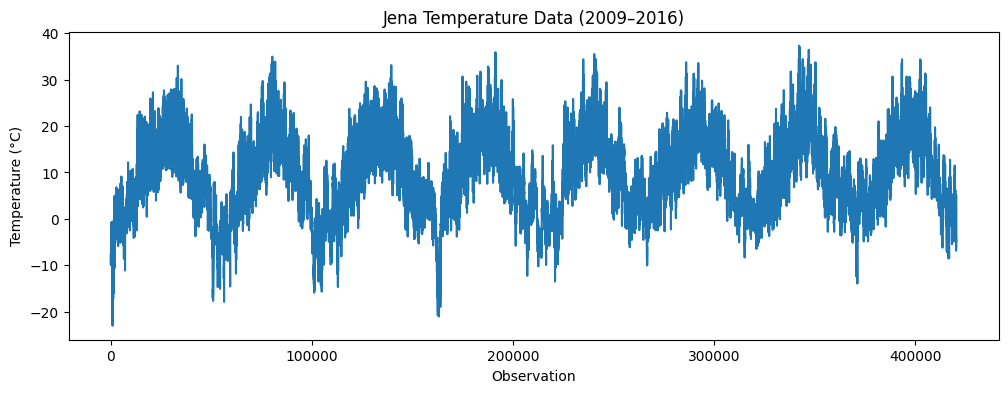

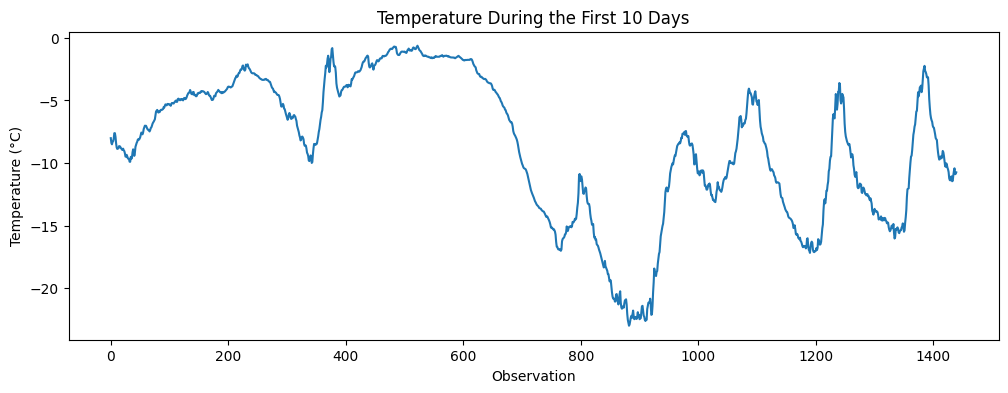

In [6]:

plt.figure(figsize=(12, 4))
plt.plot(range(len(temperature)), temperature)
plt.title("Jena Temperature Data (2009–2016)")
plt.xlabel("Observation")
plt.ylabel("Temperature (°C)")
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(range(1440), temperature[:1440])
plt.title("Temperature During the First 10 Days")
plt.xlabel("Observation")
plt.ylabel("Temperature (°C)")
plt.show()


In the next section, the data will be divided into training, validation, and test sets using the chronological splits split from the textbook example 50% for training, 25% for validation, and 25% for testing.

In [7]:

num_train_samples = int(0.5 * len(raw_data))
num_val_samples = int(0.25 * len(raw_data))
num_test_samples = len(raw_data) - num_train_samples - num_val_samples

print("Training samples:", num_train_samples)
print("Validation samples:", num_val_samples)
print("Test samples:", num_test_samples)


Training samples: 210225
Validation samples: 105112
Test samples: 105114


In the next section, normalization is performed on the weather measurements. This standardizes the weather measurements so variables with different units can be used together when training the neural networks.

In [8]:

mean = raw_data[:num_train_samples].mean(axis=0)
raw_data -= mean

std = raw_data[:num_train_samples].std(axis=0)
raw_data /= std

print("Weather data normalized.")


Weather data normalized.



## 3. Creating the Time-Series Datasets

The model will use weather measurements from the previous five days to predict the temperature 24 hours into the future. The data is sampled once per hour, with 120 observations in each sequence.


In [9]:

sampling_rate = 6
sequence_length = 120
delay = sampling_rate * (sequence_length + 24 - 1)
batch_size = 256

train_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets=temperature[delay:],
    sampling_rate=sampling_rate,
    sequence_length=sequence_length,
    shuffle=True,
    batch_size=batch_size,
    start_index=0,
    end_index=num_train_samples,
)

val_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets=temperature[delay:],
    sampling_rate=sampling_rate,
    sequence_length=sequence_length,
    shuffle=True,
    batch_size=batch_size,
    start_index=num_train_samples,
    end_index=num_train_samples + num_val_samples,
)

test_dataset = keras.utils.timeseries_dataset_from_array(
    raw_data[:-delay],
    targets=temperature[delay:],
    sampling_rate=sampling_rate,
    sequence_length=sequence_length,
    shuffle=True,
    batch_size=batch_size,
    start_index=num_train_samples + num_val_samples,
)

print("Training, validation, and test datasets created.")


Training, validation, and test datasets created.


Each batch contains 256 samples, each with 120 hourly measurements across 14 weather variables.

In [ ]:

for samples, targets in train_dataset:
    print("Samples shape:", samples.shape)
    print("Targets shape:", targets.shape)
    break


Samples shape: (256, 120, 14)
Targets shape: (256,)



## 4. Common-Sense Baseline

The baseline assumes that the temperature 24 hours from now will be the same as the most recent temperature measurement. This provides a starting point for evaluating whether the neural network models improve forecasting accuracy.


In [10]:

def evaluate_naive_method(dataset):
    total_abs_err = 0.0
    samples_seen = 0

    for samples, targets in dataset:
        preds = samples[:, -1, 1] * std[1] + mean[1]
        total_abs_err += np.sum(np.abs(preds - targets))
        samples_seen += samples.shape[0]

    return total_abs_err / samples_seen

baseline_val_mae = evaluate_naive_method(val_dataset)
baseline_test_mae = evaluate_naive_method(test_dataset)

print(f"Validation MAE: {baseline_val_mae:.2f}")
print(f"Test MAE: {baseline_test_mae:.2f}")


Validation MAE: 2.44
Test MAE: 2.62



## 5. Model 1: Stacked GRU (32, 32)

This model uses two GRU layers with 32 units each. A dropout layer of 0.5 is added after the GRU layers to help reduce overfitting. The results will be compared with the common-sense baseline.


In [ ]:

# Model 1: Stacked GRU with 32 units in each layer

inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

x = layers.GRU(32, return_sequences=True)(inputs)
x = layers.GRU(32)(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1)(x)

model1 = keras.Model(inputs, outputs)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        "jena_stacked_gru_dropout.keras", save_best_only=True
    )
]

model1.compile(optimizer="adam", loss="mse", metrics=["mae"])

history1 = model1.fit(
    train_dataset,
    epochs=50,
    validation_data=val_dataset,
    callbacks=callbacks,
)

best_val_mae1 = min(history1.history["val_mae"])
print(f"Best Validation MAE: {best_val_mae1:.2f}")


Epoch 1/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 53s 59ms/step - loss: 27.7262 - mae: 3.8651 - val_loss: 10.7544 - val_mae: 2.4802
Epoch 2/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 52s 63ms/step - loss: 14.1641 - mae: 2.8984 - val_loss: 9.0817 - val_mae: 2.3174
Epoch 3/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 51s 62ms/step - loss: 12.8651 - mae: 2.7689 - val_loss: 9.0503 - val_mae: 2.3409
Epoch 4/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 79s 58ms/step - loss: 12.0355 - mae: 2.6822 - val_loss: 9.3110 - val_mae: 2.3726
Epoch 5/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 49s 60ms/step - loss: 11.3686 - mae: 2.6047 - val_loss: 9.7401 - val_mae: 2.4171
Epoch 6/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 48s 58ms/step - loss: 10.5199 - mae: 2.5055 - val_loss: 10.3042 - val_mae: 2.4807
Epoch 7/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 46s 56ms/step - loss: 9.7561 - mae: 2.4094 - val_loss: 10.4349 - val_mae: 2.5005
Epoch 8/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 47s 57ms/step - loss: 9.1401 - mae: 2.3252 - val_loss: 11.4446 - val_mae: 2.6119
Epoch 9/50
819/819 ━━━━━━━━━━━

Below will create a graph of the training results for evaluation.

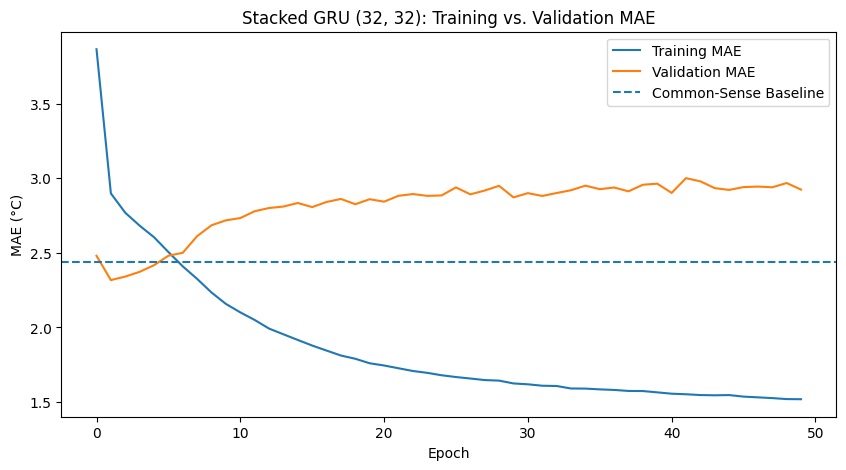

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(
    history1.history["mae"],
    label="Training MAE"
)

plt.plot(
    history1.history["val_mae"],
    label="Validation MAE"
)

plt.axhline(
    y=baseline_val_mae,
    linestyle="--",
    label="Common-Sense Baseline"
)

plt.title("Stacked GRU (32, 32): Training vs. Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (°C)")
plt.legend()
plt.show()


The graph above shows that the stacked GRU model initially performed better than the common-sense baseline, but then began overfitting as training continued. In epochs 1-3, validation MAE decreases, showing that the model initially improves. Around epoch 3, validation MAE reaches its lowest point, approximately 2.34 degrees celcius. Training MAE continues decreasing, but validation MAE increases. By epoch 50, training MAE is approximately 1.54 degrees celcius, while validation MAE is approximately 3.03 degrees celcius. The growing difference between training and validation MAE indicates overfitting. The model continues learning the training data but becomes less effective at predicting unseen observations.

In [ ]:

best_epoch1 = np.argmin(history1.history["val_mae"]) + 1
best_val_mae1 = min(history1.history["val_mae"])

print("Best epoch:", best_epoch1)
print(f"Best Validation MAE: {best_val_mae1:.4f}")


Best epoch: 2
Best Validation MAE: 2.3174


### Model 1 Results

The stacked GRU model initially improved upon the common-sense baseline, but the validation MAE began increasing after the first few epochs. Meanwhile, training MAE continued decreasing, indicating that the model was overfitting. The best-performing model was saved using ModelCheckpoint for comparison with the next experiments.


## 6. Model 2: Stacked GRU (16, 16)

This experiment reduces the number of GRU units from 32 to 16 in each layer. The purpose is to determine whether a smaller model can reduce overfitting and improve validation MAE.


In [ ]:

# Model 2: Stacked GRU with 16 units in each layer

inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

x = layers.GRU(16, return_sequences=True)(inputs)
x = layers.GRU(16)(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1)(x)

model2 = keras.Model(inputs, outputs)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        "jena_gru_16_16.keras", save_best_only=True
    )
]

model2.compile(optimizer="adam", loss="mse", metrics=["mae"])

history2 = model2.fit(
    train_dataset,
    epochs=50,
    validation_data=val_dataset,
    callbacks=callbacks,
)

best_val_mae2 = min(history2.history["val_mae"])
best_epoch2 = np.argmin(history2.history["val_mae"]) + 1

print("Best epoch:", best_epoch2)
print(f"Best Validation MAE: {best_val_mae2:.4f}")


Epoch 1/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 53s 61ms/step - loss: 45.8691 - mae: 5.0177 - val_loss: 18.4244 - val_mae: 3.1353
Epoch 2/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 50s 60ms/step - loss: 20.7881 - mae: 3.4332 - val_loss: 11.5202 - val_mae: 2.5521
Epoch 3/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 83s 61ms/step - loss: 17.8808 - mae: 3.2170 - val_loss: 10.4076 - val_mae: 2.4684
Epoch 4/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 50s 61ms/step - loss: 16.6650 - mae: 3.1124 - val_loss: 9.8625 - val_mae: 2.4177
Epoch 5/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 50s 61ms/step - loss: 15.9027 - mae: 3.0501 - val_loss: 9.5200 - val_mae: 2.3842
Epoch 6/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 49s 60ms/step - loss: 15.3159 - mae: 2.9913 - val_loss: 9.7270 - val_mae: 2.4062
Epoch 7/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 48s 59ms/step - loss: 14.6556 - mae: 2.9282 - val_loss: 9.5270 - val_mae: 2.3944
Epoch 8/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 50s 60ms/step - loss: 14.0952 - mae: 2.8731 - val_loss: 9.8308 - val_mae: 2.4319
Epoch 9/50
819/819 ━━━━━━━━━━

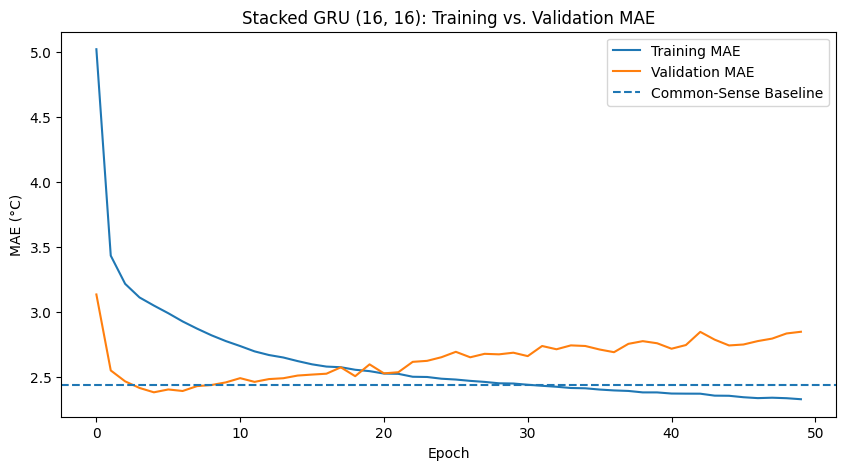

In [ ]:

plt.figure(figsize=(10, 5))

plt.plot(history2.history["mae"], label="Training MAE")
plt.plot(history2.history["val_mae"], label="Validation MAE")

plt.axhline(
    y=baseline_val_mae,
    linestyle="--",
    label="Common-Sense Baseline"
)

plt.title("Stacked GRU (16, 16): Training vs. Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (°C)")
plt.legend()
plt.show()


### Comparison of GRU Models

Both stacked GRU models performed better than the common-sense baseline. The model with 32 units in each layer achieved the lowest validation MAE of 2.3477°C, compared with 2.3842°C for the model with 16 units. Reducing the number of units did not improve forecasting accuracy in this experiment.


## 7. Model 3: Stacked LSTM (32, 32)

This experiment replaces the GRU layers with LSTM layers while keeping the number of units the same. The purpose is to compare the performance of the two recurrent neural network architectures.


In [11]:

# Model 3: Stacked LSTM with 32 units in each layer

inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

x = layers.LSTM(32, return_sequences=True)(inputs)
x = layers.LSTM(32)(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1)(x)

model3 = keras.Model(inputs, outputs)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        "jena_lstm_32_32.keras", save_best_only=True
    )
]

model3.compile(optimizer="adam", loss="mse", metrics=["mae"])

history3 = model3.fit(
    train_dataset,
    epochs=50,
    validation_data=val_dataset,
    callbacks=callbacks,
)

best_val_mae3 = min(history3.history["val_mae"])
best_epoch3 = np.argmin(history3.history["val_mae"]) + 1

print("Best epoch:", best_epoch3)
print(f"Best Validation MAE: {best_val_mae3:.4f}")


Epoch 1/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 54s 61ms/step - loss: 33.2392 - mae: 4.2063 - val_loss: 12.4544 - val_mae: 2.6809
Epoch 2/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 50s 61ms/step - loss: 14.3992 - mae: 2.9140 - val_loss: 10.5881 - val_mae: 2.5156
Epoch 3/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 48s 59ms/step - loss: 13.5404 - mae: 2.8343 - val_loss: 10.2394 - val_mae: 2.5013
Epoch 4/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 53s 64ms/step - loss: 11.8640 - mae: 2.6470 - val_loss: 10.5813 - val_mae: 2.5556
Epoch 5/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 51s 63ms/step - loss: 11.0368 - mae: 2.5481 - val_loss: 10.5813 - val_mae: 2.5648
Epoch 6/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 50s 61ms/step - loss: 10.2392 - mae: 2.4462 - val_loss: 11.0347 - val_mae: 2.6194
Epoch 7/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 50s 61ms/step - loss: 9.5171 - mae: 2.3512 - val_loss: 11.0006 - val_mae: 2.6335
Epoch 8/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 49s 59ms/step - loss: 9.3309 - mae: 2.3246 - val_loss: 10.5144 - val_mae: 2.5648
Epoch 9/50
819/819 ━━━━━━━

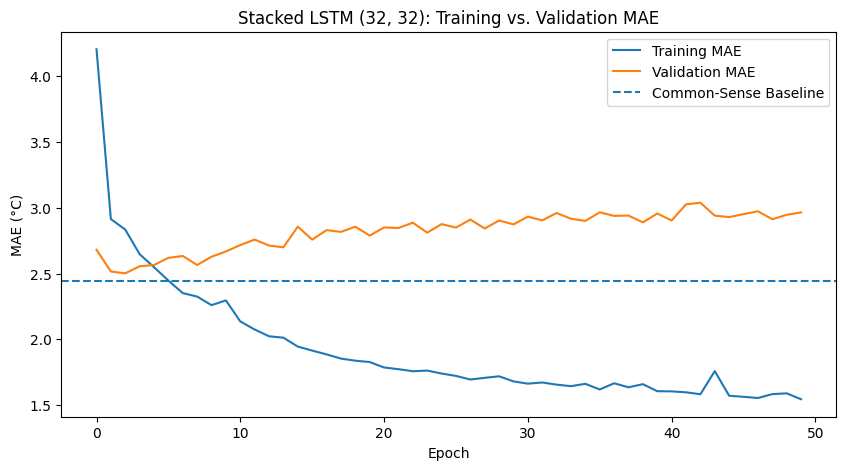

In [12]:

plt.figure(figsize=(10, 5))

plt.plot(history3.history["mae"], label="Training MAE")
plt.plot(history3.history["val_mae"], label="Validation MAE")

plt.axhline(
    y=baseline_val_mae,
    linestyle="--",
    label="Common-Sense Baseline"
)

plt.title("Stacked LSTM (32, 32): Training vs. Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (°C)")
plt.legend()
plt.show()


### Model 3 Results

The stacked LSTM model with 32 units in each layer achieved its lowest validation MAE of 2.5013°C at epoch 3. After this point, validation MAE increased while training MAE continued decreasing, indicating overfitting. The LSTM model did not outperform the common-sense baseline or either of the stacked GRU models.

In [13]:

import os

print("Model 1 checkpoint exists:",
      os.path.exists("jena_stacked_gru_dropout.keras"))


Model 1 checkpoint exists: False



## 8. Final Model: Stacked GRU (32, 32)

The stacked GRU model with 32 units in each layer achieved the lowest validation MAE of the three models tested. This model will be retrained and its best-performing version saved for final evaluation using the test dataset.


In [14]:

# Retrain the best-performing GRU model

inputs = keras.Input(shape=(sequence_length, raw_data.shape[-1]))

x = layers.GRU(32, return_sequences=True)(inputs)
x = layers.GRU(32)(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1)(x)

final_model = keras.Model(inputs, outputs)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        "jena_gru_final.keras",
        monitor="val_mae",
        mode="min",
        save_best_only=True
    )
]

final_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

final_history = final_model.fit(
    train_dataset,
    epochs=50,
    validation_data=val_dataset,
    callbacks=callbacks
)

print("Best epoch:",
      np.argmin(final_history.history["val_mae"]) + 1)

print(f"Best Validation MAE: {min(final_history.history['val_mae']):.4f}")


Epoch 1/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 53s 63ms/step - loss: 28.4337 - mae: 3.9116 - val_loss: 11.0681 - val_mae: 2.5182
Epoch 2/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 53s 64ms/step - loss: 14.1750 - mae: 2.8960 - val_loss: 9.5342 - val_mae: 2.3739
Epoch 3/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 52s 64ms/step - loss: 12.8171 - mae: 2.7631 - val_loss: 9.3749 - val_mae: 2.3680
Epoch 4/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 52s 63ms/step - loss: 11.9221 - mae: 2.6687 - val_loss: 9.5925 - val_mae: 2.3867
Epoch 5/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 50s 61ms/step - loss: 11.1221 - mae: 2.5720 - val_loss: 10.1884 - val_mae: 2.4605
Epoch 6/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 49s 59ms/step - loss: 10.3701 - mae: 2.4793 - val_loss: 10.6785 - val_mae: 2.5156
Epoch 7/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 49s 59ms/step - loss: 9.5521 - mae: 2.3760 - val_loss: 10.9919 - val_mae: 2.5642
Epoch 8/50
819/819 ━━━━━━━━━━━━━━━━━━━━ 83s 61ms/step - loss: 8.8930 - mae: 2.2877 - val_loss: 11.8385 - val_mae: 2.6440
Epoch 9/50
819/819 ━━━━━━━━━━

In [15]:

# Load the best-performing model
best_model = keras.models.load_model("jena_gru_final.keras")

# Evaluate on the test dataset
test_results = best_model.evaluate(test_dataset)

print(f"Final Test MAE: {test_results[1]:.4f}")


405/405 ━━━━━━━━━━━━━━━━━━━━ 15s 36ms/step - loss: 10.4358 - mae: 2.5237
Final Test MAE: 2.5237


## 9. Conclusions

This assignment compared recurrent neural network models for predicting temperatures 24 hours in advance using the Jena Climate dataset.

The stacked GRU model with 32 units in each layer achieved the lowest validation MAE of 2.3477°C in the initial experiments. Reducing the number of GRU units to 16 increased the validation MAE to 2.3842°C. Replacing the GRU layers with LSTM layers also resulted in a higher validation MAE of 2.5013°C.

All three models showed signs of overfitting as training continued, with training MAE decreasing while validation MAE increased.

The selected GRU architecture was retrained and evaluated on the test dataset, achieving a test MAE of 2.5237°C. This was better than the common-sense baseline test MAE of 2.62°C, representing an improvement of approximately 3.68%.

Overall, the results suggest that increasing the number of recurrent units improved forecasting accuracy in this experiment, while replacing GRU layers with LSTM layers did not improve performance.

In [16]:

print("Final model best epoch:",
      np.argmin(final_history.history["val_mae"]) + 1)

print(f"Final model best validation MAE: {min(final_history.history['val_mae']):.4f}")


Final model best epoch: 3
Final model best validation MAE: 2.3680



## 9. Model Comparison

| Model | Best Epoch | Validation MAE | Test MAE |
|---|---:|---:|---:|
| Common-Sense Baseline | — | 2.4400 | 2.6200 |
| Stacked GRU (32, 32) | 3 | 2.3477 | — |
| Stacked GRU (16, 16) | 5 | 2.3842 | — |
| Stacked LSTM (32, 32) | 3 | 2.5013 | — |
| Final Stacked GRU (32, 32) | 3 | 2.3680 | 2.5237 |

The stacked GRU model with 32 units in each layer achieved the lowest validation MAE in the initial experiments. When retrained for final testing, the model achieved a test MAE of 2.5237°C, improving upon the common-sense baseline of 2.62°C.


## 10. Conclusions

This assignment compared recurrent neural network models for forecasting temperature 24 hours into the future using the Jena Climate dataset.

The stacked GRU model with 32 units in each layer achieved the lowest validation MAE of 2.3477°C. Reducing the number of units to 16 increased the validation MAE to 2.3842°C, while replacing the GRU layers with LSTM layers resulted in a validation MAE of 2.5013°C.

The models showed signs of overfitting because training MAE continued to decrease while validation MAE increased. The best validation results occurred within the first five epochs.

The best-performing architecture was retrained and achieved a validation MAE of 2.3680°C and a test MAE of 2.5237°C. Compared with the common-sense test baseline of 2.62°C, the final model reduced forecasting error by approximately 3.68%.

Overall, the stacked GRU model with 32 units performed best among the architectures tested. Increasing the number of recurrent units improved performance compared with the smaller GRU model, while using LSTM instead of GRU did not produce better results.